# 4. Joins and Topological Operations

In [1]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
nl_gpkg_path = Path('../data/outputs/netherlands.gpkg')

provinces = gpd.read_file(nl_gpkg_path, layer='provinces')
cities = gpd.read_file(nl_gpkg_path, layer='cities')

enschede = cities[
    cities['name']=='Enschede'
]

enschede.head(1)

,name,geometry
81,Enschede,"MULTIPOLYGON (((252038.609 465222.168, 252046...."


In [3]:
n_hood_path = Path('/home/lorem/Data/WijkBuurtkaart_2026_v0.gpkg')

gpd.list_layers(n_hood_path)

,name,geometry_type
0,buurten,MultiPolygon Z
1,gemeenten,MultiPolygon Z
2,wijken,MultiPolygon Z


Download the above file: https://www.cbs.nl/nl-nl/dossier/nederland-regionaal/geografische-data/wijk-en-buurtkaart

In [4]:
n_hoods = gpd.read_file(n_hood_path, layer='buurten')
n_hoods.head(1)

,jrstatcode,bu_code,bu_naam,jrwk,wk_code,wk_naam,jrgm,gm_code,gm_naam,water,jaar,geometry
0,2026BU00140000,BU00140000,Binnenstad-Noord,2026WK001400,WK001400,Centrum,2026GM0014,GM0014,Groningen,NEE,2026,"MULTIPOLYGON Z (((233836.216 582380.178 0, 233..."


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

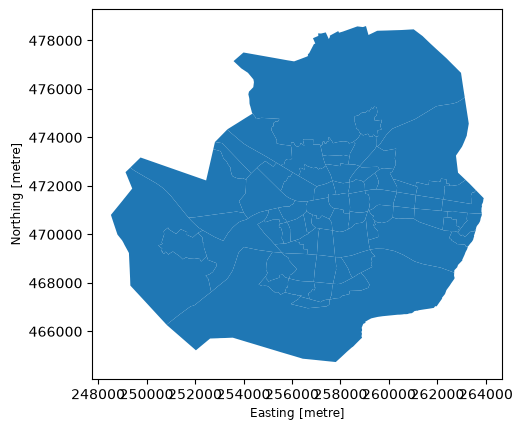

In [5]:
enschede_n_hoods = n_hoods[
    n_hoods['gm_naam'] == 'Enschede'
]

enschede_n_hoods.plot()

In [6]:
enschede_n_hoods = pd.merge(
    enschede,
    n_hoods,
    left_on='name',
    right_on='gm_naam'
)

enschede_n_hoods.head(1)

,name,geometry_x,jrstatcode,bu_code,bu_naam,jrwk,wk_code,wk_naam,jrgm,gm_code,gm_naam,water,jaar,geometry_y
0,Enschede,"MULTIPOLYGON (((252038.609 465222.168, 252046....",2026BU01530000,BU01530000,City,2026WK015300,WK015300,Wijk 00 Binnensingelgebied,2026GM0153,GM0153,Enschede,NEE,2026,"MULTIPOLYGON Z (((258308 471708.09 0, 258316.0..."


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

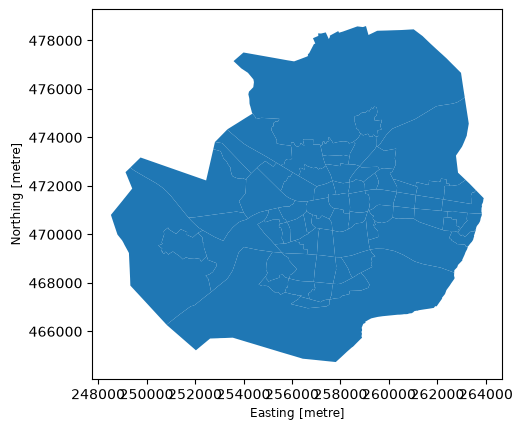

In [7]:
enschede_n_hoods = enschede_n_hoods.set_geometry('geometry_y')
enschede_n_hoods.plot()

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

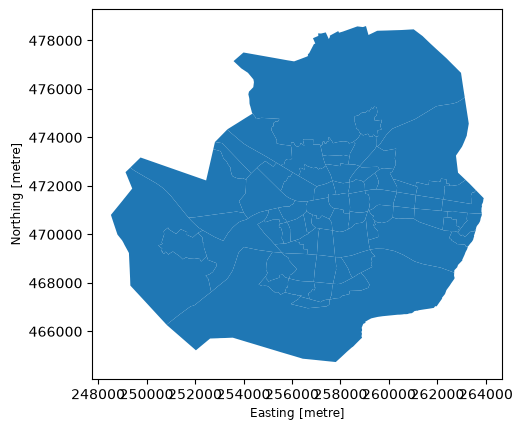

In [8]:
enschede_n_hoods = n_hoods[
    n_hoods['gm_naam']==enschede['name'].iloc[0]
]

enschede_n_hoods.plot()

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

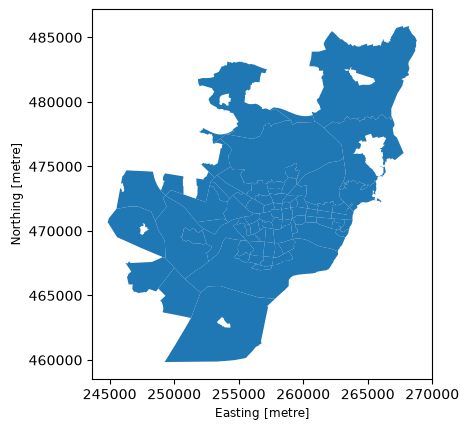

In [9]:
#default predicate: intersects
#default how: inner
enschede_n_hoods = gpd.sjoin(
    n_hoods,
    enschede
)

enschede_n_hoods.plot()

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

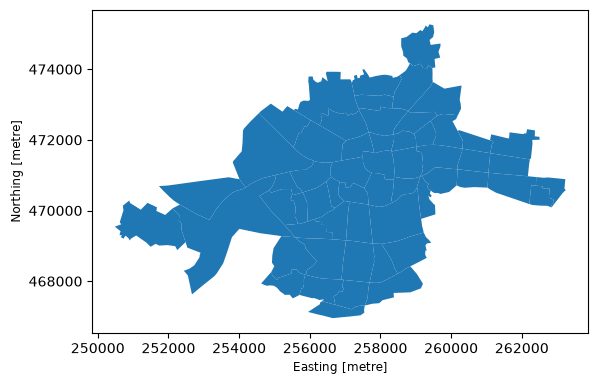

In [10]:
#default predicate: intersects
#default how: inner
enschede_n_hoods = gpd.sjoin(
    n_hoods,
    enschede,
    predicate='covered_by'
)

enschede_n_hoods.plot()

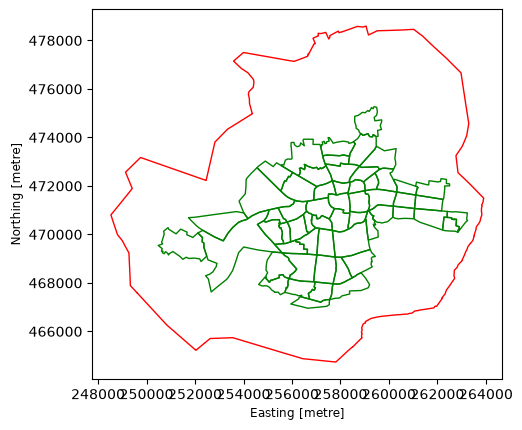

In [11]:
fig, ax = plt.subplots()

enschede_n_hoods.plot(
    ax=ax,
    color='none',
    edgecolor='green'
)

enschede.plot(
    ax=ax,
    color='none',
    edgecolor='red'
)

plt.show()

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

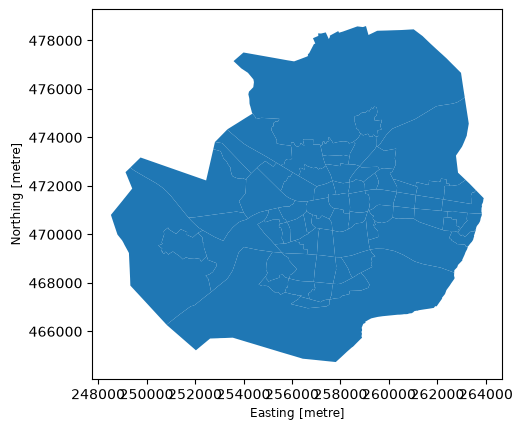

In [12]:
points = n_hoods.copy()
points.geometry = n_hoods.geometry.representative_point()

matches = gpd.sjoin(
    points,
    enschede
)

enschede_n_hoods = n_hoods.loc[matches.index]
enschede_n_hoods.plot()

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

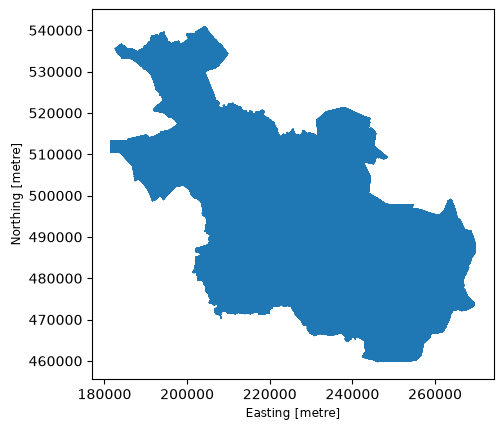

In [13]:
overijssel = provinces[
    provinces['name']=='Overijssel'
]

overijssel_cities = overijssel.sjoin(
    cities,
    predicate='contains'
)

overijssel_cities.plot()

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

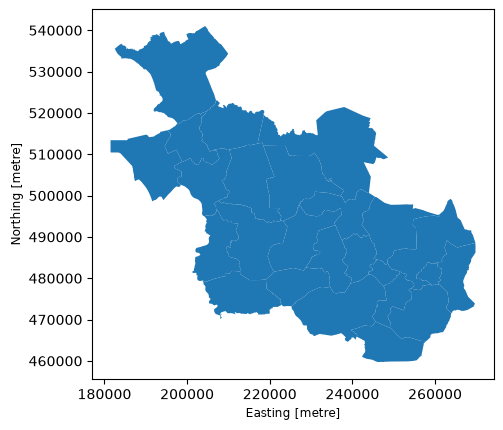

In [14]:
overijssel_cities = cities.sjoin(
    overijssel,
    predicate='within'
)

overijssel_cities.plot()

In [15]:
n_hood_stats_path = Path('../data/inputs/kwb_2025.xlsx')

n_hood_stats = pd.read_excel(n_hood_stats_path)
n_hood_stats.head()

,gwb_code_10,gwb_code_8,regio,gm_naam,recs,gwb_code,ind_wbi,a_inw,a_man,a_vrouw,...,g_afs_kv,g_afs_sc,g_3km_sc,a_opp_ha,a_lan_ha,a_wat_ha,pst_mvp,pst_dekp,ste_mvs,ste_oad
0,NL00,0000,Nederland,Nederland,Land,NL00,.,18044027,8978451,9065576,...,0.7,0.8,9.8,4154337,3364723,789614,NaN,NaN,2,2082
1,GM0014,0014,Groningen,Groningen,Gemeente,GM0014,1,244441,121379,123062,...,0.6,0.8,8.9,19796,18553,1244,NaN,NaN,1,3487
2,WK001400,001400,Centrum,Groningen,Wijk,WK001400,1,24980,12790,12185,...,0.5,0.8,14.1,241,228,13,NaN,NaN,1,6823
3,BU00140000,00140000,Binnenstad-Noord,Groningen,Buurt,BU00140000,1,4765,2495,2270,...,0.6,0.5,15.1,39,37,2,9712,1,1,7062
4,BU00140001,00140001,Binnenstad-Zuid,Groningen,Buurt,BU00140001,1,7085,3645,3440,...,0.5,0.9,13.3,59,55,4,9711,1,1,6765


In [16]:
enschede_stats = pd.merge(
    enschede_n_hoods,
    n_hood_stats,
    left_on='bu_code',
    right_on='gwb_code_10'
)

enschede_stats = enschede_stats[[
    'bu_code',
    'bu_naam',
    'a_inw',
    'geometry'
]]

enschede_stats['area_sqkm'] = round((enschede_stats.geometry.area / 10**6), 2)
enschede_stats['pop_den'] = round((enschede_stats['a_inw'] / enschede_stats['area_sqkm']), 2)

enschede_stats.head()

,bu_code,bu_naam,a_inw,geometry,area_sqkm,pop_den
0,BU01530000,City,3905,"MULTIPOLYGON Z (((258308 471708.09 0, 258316.0...",0.56,6973.21
1,BU01530001,"Lasonder, Zeggelt",2030,"MULTIPOLYGON Z (((257725.75 472208.592 0, 2578...",0.29,7000.00
2,BU01530002,De Laares,2440,"MULTIPOLYGON Z (((258844.192 472226.055 0, 258...",0.30,8133.33
3,BU01530003,De Bothoven,5960,"MULTIPOLYGON Z (((259028.971 471678.53 0, 2591...",0.65,9169.23
4,BU01530004,Hogeland-Noord,2995,"MULTIPOLYGON Z (((259026.93 470647.06 0, 25898...",0.35,8557.14


In [17]:
enschede_stats.explore(
    column='pop_den',
    cmap='RdYlGn_r'
)

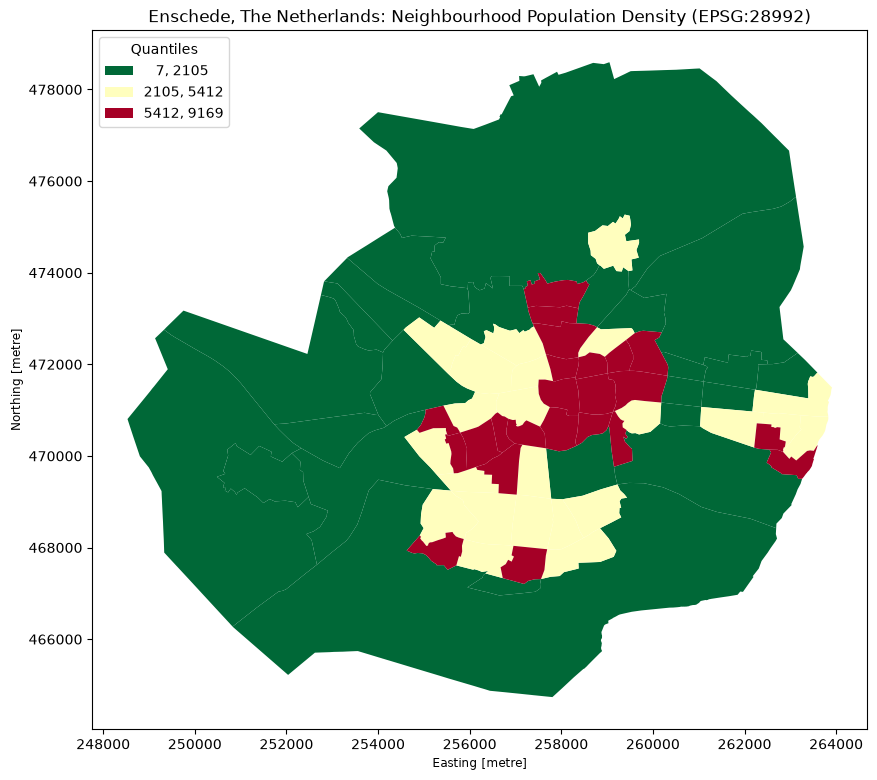

In [18]:
fig, ax = plt.subplots(figsize=(10,10))

enschede_stats.plot(
    ax=ax,
    column='pop_den',
    scheme='Quantiles',
    k=3,
    cmap='RdYlGn_r',
    legend=True,
    legend_kwds={
        'fmt':'{:.0f}',
        'title':'Quantiles',
        'loc':'upper left'
    }
)

ax.set(
    title=f'Enschede, The Netherlands: Neighbourhood Population Density ({enschede_stats.crs})'
)

plt.show()